<a href="https://colab.research.google.com/github/alialnefaie4-oss/ali-abdulmalik/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/SDAIAAcademy/international-airpassengers-project.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report


fatal: destination path '/content/proj' already exists and is not an empty directory.
/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for international-airpassengers-project (pyproject.toml) ... done


In [21]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"] .astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)

In [22]:
n_obs = len(df)
range_ = (df["ds"].min(), df["ds"].max())
n_gaps = df["ds"].isna().sum() # أو التأكد من انتظام الشهور بدون فجوات
print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")

144 months, 1949-01-01 to 1960-12-01, 0 gaps


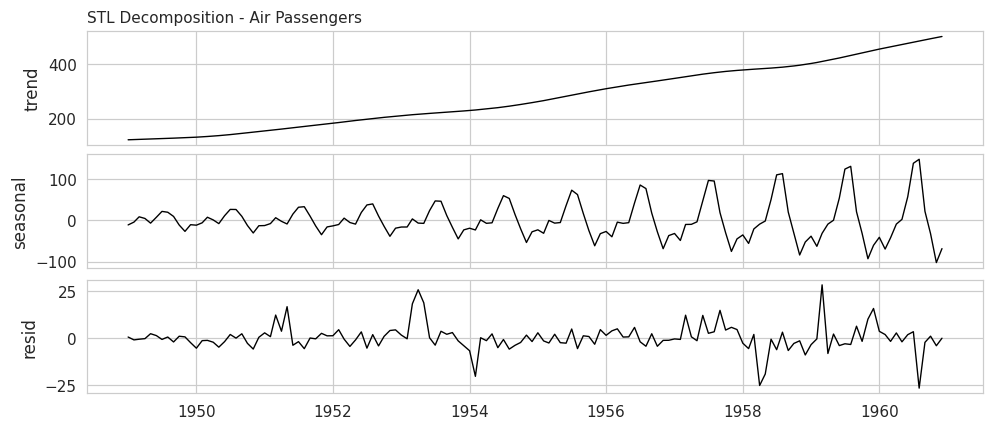

In [23]:
from statsmodels.tsa.seasonal import STL

# 1. إجراء تحليل STL
stl = STL(df["y"], period=12, robust=True)
result = stl.fit()

# 2. وضع النتائج في DataFrame لكي يتوافق مع دالة الرسم في coursekit
dcmp = pd.DataFrame({
    "ds": df["ds"],
    "trend": result.trend,
    "seasonal": result.seasonal,
    "resid": result.resid,
})

# 3. رسم المكونات
P.decomposition_plot(
    dcmp,
    cols=["trend", "seasonal", "resid"],
    title="STL Decomposition - Air Passengers",
    x="ds"
)
plt.show()

In [24]:
# حساب قوة الاتجاه والموسمية رياضياً بناءً على الصيغ القياسية لـ STL
def compute_strength(component, residual):
    detrended = df["y"] - component
    val = 1 - np.var(residual) / np.var(detrended)
    return max(0, val)

trend_comp = dcmp.trend
seasonal_comp = dcmp.seasonal
resid_comp = dcmp.resid

trend_strength = max(0, 1 - np.var(resid_comp) / np.var(resid_comp + trend_comp))
seasonal_strength = max(0, 1 - np.var(resid_comp) / np.var(resid_comp + seasonal_comp))

print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")

trend strength: 1.00
seasonal strength: 0.98


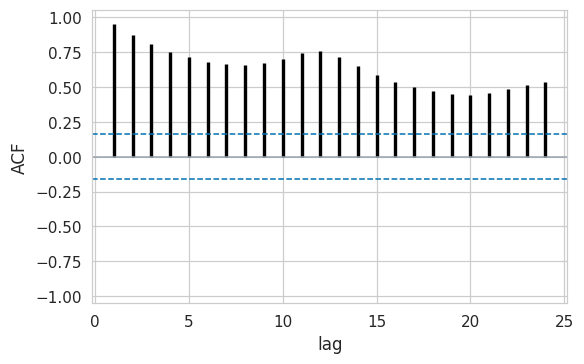

In [25]:
P.acf_plot(df["y"], nlags=24)
plt.show()

In [26]:
!pip install -q "autogluon.timeseries"

In [27]:
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

# إعداد البيانات لـ AutoGluon إذا لم تكن جاهزة
ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
tsdf = TimeSeriesDataFrame.from_data_frame(
    ag_long, id_column="item_id", timestamp_column="timestamp")
ag_train = tsdf.slice_by_timestep(None, -12)

# تعريف النماذج وتدريبها
ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
       "AutoARIMA": {}, "Theta": {}}

predictor = TimeSeriesPredictor(
    prediction_length=12, target="y", eval_metric="MASE",
    freq="MS", verbosity=1)
predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [28]:
leaderboard_df = predictor.leaderboard(tsdf, silent=True)
display(leaderboard_df)

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,AutoARIMA,-0.608073,-1.575987,0.718244,0.112347,0.015136,5
1,Theta,-0.875371,-1.633923,0.059362,0.013304,0.014251,3
2,WeightedEnsemble,-0.929514,-1.535792,1.346096,0.212074,0.278029,6
3,AutoETS,-1.169539,-1.554323,0.622572,0.098134,0.016701,4
4,SeasonalNaive,-1.570881,-1.656513,0.040778,0.007612,0.014405,2
5,Naive,-2.495895,-3.196371,0.028049,0.008106,0.016273,1


In [29]:
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA # أو النموذج الذي اخترته من لوحة الصدارة
from coursekit import scoring

# 1. إعداد النموذج المختار
MY_MODEL = AutoARIMA(season_length=SEASON_LENGTH)
MY_NAME = "AutoARIMA"

# 2. تشغيل التحقق المتقاطع
mysf = StatsForecast(models=[MY_MODEL], freq="MS", n_jobs=1)
mycv = mysf.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)

# عرض أول أسطر النتائج للتأكد من نجاح العملية
display(mycv.head())

,unique_id,ds,cutoff,y,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-lo-80,AutoARIMA-lo-60,AutoARIMA-lo-40,AutoARIMA-lo-20,AutoARIMA-hi-20,AutoARIMA-hi-40,AutoARIMA-hi-60,AutoARIMA-hi-80,AutoARIMA-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,200.033960,186.129327,190.942209,194.063221,196.313689,198.236632,201.831289,203.754231,206.004700,209.125712,213.938594
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,205.951260,191.099431,196.240171,199.573789,201.977561,204.031496,207.871024,209.924959,212.328732,215.662349,220.803089
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,228.492818,210.220348,216.545092,220.646501,223.603906,226.130899,230.854738,233.381731,236.339136,240.440545,246.765289
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,214.413179,194.752951,201.558047,205.970950,209.152963,211.871877,216.954482,219.673395,222.855409,227.268312,234.073408
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,220.835055,199.055069,206.593888,211.482588,215.007685,218.019750,223.650360,226.662425,230.187522,235.076222,242.615041


In [30]:
from statsforecast.models import AutoARIMA # أو AutoETS بناءً على الفائز في AutoGluon

MY_MODEL = AutoARIMA(season_length=SEASON_LENGTH)
MY_NAME = "AutoARIMA"

mysf = StatsForecast(models=[MY_MODEL], freq="MS", n_jobs=1)
mycv = mysf.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)

# دمج النتائج في جدول واحد للمقارنة
# يمكنك استخدام أدوات التقييم المقررة في coursekit.scoring لتقييم المقاييس (MASE, RMSSE, CRPS, Coverage)

In [33]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoARIMA
from coursekit import scoring

# 1. تشغيل التحقق المتقاطع لخط الأساس (SeasonalNaive) لتوليد cv
floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)], freq="MS", n_jobs=1)
cv = floor_sf.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)

# 2. تشغيل التحقق المتقاطع لنموذج AutoARIMA لتوليد mycv (إذا لم يكن معرفاً)
mysf = StatsForecast(models=[AutoARIMA(season_length=SEASON_LENGTH)], freq="MS", n_jobs=1)
mycv = mysf.cross_validation(df=df, h=H, step_size=H, n_windows=8, level=scoring.LEVELS)

# 3. عرض أعمدة النتائج للتأكد من جاهزيتها
print("SeasonalNaive columns:", cv.columns.tolist())
print("My Model columns:", mycv.columns.tolist())

SeasonalNaive columns: ['unique_id', 'ds', 'cutoff', 'y', 'SeasonalNaive', 'SeasonalNaive-lo-20', 'SeasonalNaive-lo-40', 'SeasonalNaive-lo-60', 'SeasonalNaive-lo-80', 'SeasonalNaive-lo-95', 'SeasonalNaive-hi-20', 'SeasonalNaive-hi-40', 'SeasonalNaive-hi-60', 'SeasonalNaive-hi-80', 'SeasonalNaive-hi-95']
My Model columns: ['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA', 'AutoARIMA-lo-95', 'AutoARIMA-lo-80', 'AutoARIMA-lo-60', 'AutoARIMA-lo-40', 'AutoARIMA-lo-20', 'AutoARIMA-hi-20', 'AutoARIMA-hi-40', 'AutoARIMA-hi-60', 'AutoARIMA-hi-80', 'AutoARIMA-hi-95']
